In [30]:
import math
import os
import glob

import onnx
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

import onnx2tf
import tensorflow as tf
print("TensorFlow version: ", tf.__version__)

TensorFlow version:  2.17.0


In [31]:
def load_model(model_path):
    interpreter = tf.lite.Interpreter(model_path=model_path)
    interpreter.allocate_tensors()
    return interpreter

In [32]:
def model2onnx(file_path: str, model: nn.Module, x: np.ndarray, simplify=False):
    os.makedirs(os.path.dirname(file_path), exist_ok=True)

    torch.onnx.export(
        model,
        torch.Tensor(x),
        file_path,
        input_names=["input_0"],
        output_names=["output_0"],
    )

    if simplify:
        import onnxslim

        model_onnx = onnx.load(file_path)
        model_onnx = onnxslim.slim(model_onnx)
        onnx.save(model_onnx, file_path)

In [33]:
class Dummy(nn.Module):
    def __init__(self):
        super().__init__()
        self.sigm = nn.Sigmoid()

    def forward(self, x):
        return self.sigm(x)

torch.Size([100])


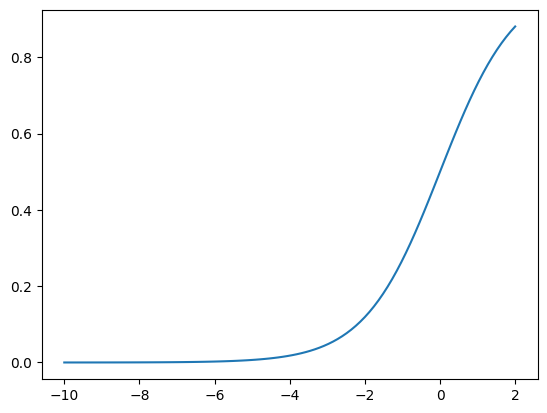

In [144]:
LIMIT_MIN = -10
LIMIT_MAX = 2
x = torch.linspace(LIMIT_MIN, LIMIT_MAX, 100, dtype=torch.float32)
print(x.shape)

model = Dummy()
model.eval()
y = model(x[None])

plt.plot(x.numpy(), y.detach().numpy()[0])

In [145]:
model2onnx("dummy_saved_model/dummy.onnx", model, x.numpy()[None], simplify=True)

In [146]:
# x.numpy()[None]
# x_norm = (x - x.min()) / (x.max() - x.min())

# np.save("dummy_saved_model/x_norm.npy", x_norm.numpy())
# np.save("dummy_saved_model/x.npy", x.numpy())

# onnx2tf.convert(
#     input_onnx_file_path="dummy_saved_model/dummy.onnx",
#     output_folder_path="dummy_saved_model",
#     not_use_onnxsim=True,
#     verbosity=True,
#     # keep_ncw_or_nchw_or_ncdhw_input_names=["input_0"],
#     output_integer_quantized_tflite=True,
#     input_output_quant_dtype="uint8",
#     quant_type="per-tensor",
#     custom_input_op_name_np_data_path=[[
#         "input_0", "dummy_saved_model/x_norm.npy", [[0]], [[1]]
#     ]],
#     disable_group_convolution=True,  # for end-to-end model compatibility
#     enable_batchmatmul_unfold=True,  # for end-to-end model compatibility
# )

In [147]:
# x.numpy()[None]
# x_norm = (x - x.min()) / (x.max() - x.min()) * 255

# np.save("dummy_saved_model/x_norm.npy", x_norm.numpy()[None])
# np.save("dummy_saved_model/x.npy", x.numpy())

# onnx2tf.convert(
#     input_onnx_file_path="dummy_saved_model/dummy.onnx",
#     output_folder_path="dummy_saved_model",
#     not_use_onnxsim=True,
#     verbosity=True,
#     copy_onnx_input_output_names_to_tflite=True,
#     output_integer_quantized_tflite=True,
#     input_output_quant_dtype="uint8",
#     quant_type="per-tensor",
#     custom_input_op_name_np_data_path=[[
#         "input_0", "dummy_saved_model/x_norm.npy", [[127.5]], [[25]]
#     ]],
#     disable_group_convolution=True,  # for end-to-end model compatibility
#     enable_batchmatmul_unfold=True,  # for end-to-end model compatibility
# )

In [148]:
# # x_norm = (x - x.min()) / (x.max() - x.min()) * 255
# x_min = 0
# x_max = 1
# x_norm = (x - x_min) / (x_max - x_min) * 255

# np.save("dummy_saved_model/x_norm.npy", x_norm.numpy()[None])
# np.save("dummy_saved_model/x.npy", x.numpy()[None])

# onnx2tf.convert(
#     input_onnx_file_path="dummy_saved_model/dummy.onnx",
#     output_folder_path="dummy_saved_model",
#     not_use_onnxsim=True,
#     verbosity=True,
#     copy_onnx_input_output_names_to_tflite=True,
#     output_integer_quantized_tflite=True,
#     input_output_quant_dtype="uint8",
#     quant_type="per-tensor",
#     custom_input_op_name_np_data_path=[[
#         "input_0", "dummy_saved_model/x_norm.npy", [[0]], [[255]]
#     ]],
#     disable_group_convolution=True,  # for end-to-end model compatibility
#     enable_batchmatmul_unfold=True,  # for end-to-end model compatibility
# )

In [149]:
# a = np.random.randn(100)

# a = (a - a.min()) / (a.max() - a.min()) * 255

# np.save("dummy_saved_model/a.npy", a[None])

# onnx2tf.convert(
#     input_onnx_file_path="dummy_saved_model/dummy.onnx",
#     output_folder_path="dummy_saved_model",
#     not_use_onnxsim=True,
#     verbosity=True,
#     copy_onnx_input_output_names_to_tflite=True,
#     output_integer_quantized_tflite=True,
#     input_output_quant_dtype="uint8",
#     quant_type="per-tensor",
#     custom_input_op_name_np_data_path=[[
#         "input_0", "dummy_saved_model/a.npy", [[0]], [[255]]
#     ]],
#     disable_group_convolution=True,  # for end-to-end model compatibility
#     enable_batchmatmul_unfold=True,  # for end-to-end model compatibility
# )

In [150]:
x_norm = (x - x.min()) / (x.max() - x.min()) * 255


np.save("dummy_saved_model/x_norm.npy", x_norm.numpy()[None])
np.save("dummy_saved_model/x.npy", x.numpy()[None])

onnx2tf.convert(
    input_onnx_file_path="dummy_saved_model/dummy.onnx",
    output_folder_path="dummy_saved_model",
    not_use_onnxsim=True,
    verbosity=True,
    copy_onnx_input_output_names_to_tflite=True,
    output_integer_quantized_tflite=True,
    input_output_quant_dtype="uint8",
    quant_type="per-tensor",
    custom_input_op_name_np_data_path=[[
        "input_0", "dummy_saved_model/x_norm.npy", [[255 * np.abs(LIMIT_MIN) / (LIMIT_MAX - LIMIT_MIN)]], [[255 / (LIMIT_MAX - LIMIT_MIN)]]  # 255 / 2 for mean, 255 / (LIMIT * 2) for std
    ]],
    disable_group_convolution=True,  # for end-to-end model compatibility
    enable_batchmatmul_unfold=True,  # for end-to-end model compatibility
)


Automatic generation of each OP name started ========================================
Automatic generation of each OP name complete!

Model loaded ========================================================================

Model conversion started ============================================================
saved_model output started ==========================================================
saved_model output complete!
wget https://github.com/PINTO0309/onnx2tf/releases/download/1.16.31/flatc.tar.gz && tar -zxvf flatc.tar.gz && sudo chmod +x flatc && sudo mv flatc /usr/bin/
Float32 tflite output complete!
wget https://github.com/PINTO0309/onnx2tf/releases/download/1.16.31/flatc.tar.gz && tar -zxvf flatc.tar.gz && sudo chmod +x flatc && sudo mv flatc /usr/bin/
Float16 tflite output complete!


I0000 00:00:1753967191.779360 1105878 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0
W0000 00:00:1753967191.788160 1105878 tf_tfl_flatbuffer_helpers.cc:392] Ignored output_format.
W0000 00:00:1753967191.788174 1105878 tf_tfl_flatbuffer_helpers.cc:395] Ignored drop_control_dependency.
I0000 00:00:1753967191.808096 1105878 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0
W0000 00:00:1753967191.817503 1105878 tf_tfl_flatbuffer_helpers.cc:392] Ignored output_format.
W0000 00:00:1753967191.817516 1105878 tf_tfl_flatbuffer_helpers.cc:395] Ignored drop_control_dependency.
I0000 00:00:1753967191.837734 1105878 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0
W0000 00:00:1753967191.845987 1105878 tf_tfl_flatbuffer_helpers.cc:392] Ignored output_format.
W0000 00:00:1753967191.845999 1105878 tf_tfl_flatbuffer_helpers.cc:395] Ignored drop_control_dependency.
W0000 00:00:1753967191.92

wget https://github.com/PINTO0309/onnx2tf/releases/download/1.16.31/flatc.tar.gz && tar -zxvf flatc.tar.gz && sudo chmod +x flatc && sudo mv flatc /usr/bin/
Dynamic Range Quantization tflite output complete!
Input signature information for quantization
signature_name: serving_default
input_name.0: input_0 shape: (1, 100) dtype: <dtype: 'float32'>
wget https://github.com/PINTO0309/onnx2tf/releases/download/1.16.31/flatc.tar.gz && tar -zxvf flatc.tar.gz && sudo chmod +x flatc && sudo mv flatc /usr/bin/
INT8 Quantization tflite output complete!
wget https://github.com/PINTO0309/onnx2tf/releases/download/1.16.31/flatc.tar.gz && tar -zxvf flatc.tar.gz && sudo chmod +x flatc && sudo mv flatc /usr/bin/
Full INT8 Quantization tflite output complete!
wget https://github.com/PINTO0309/onnx2tf/releases/download/1.16.31/flatc.tar.gz && tar -zxvf flatc.tar.gz && sudo chmod +x flatc && sudo mv flatc /usr/bin/
INT8 Quantization with int16 activations tflite output complete!
wget https://github.com/PI

W0000 00:00:1753967191.969915 1105878 tf_tfl_flatbuffer_helpers.cc:392] Ignored output_format.
W0000 00:00:1753967191.969930 1105878 tf_tfl_flatbuffer_helpers.cc:395] Ignored drop_control_dependency.
fully_quantize: 0, inference_type: 6, input_inference_type: UINT8, output_inference_type: UINT8
W0000 00:00:1753967192.017051 1105878 tf_tfl_flatbuffer_helpers.cc:392] Ignored output_format.
W0000 00:00:1753967192.017068 1105878 tf_tfl_flatbuffer_helpers.cc:395] Ignored drop_control_dependency.
W0000 00:00:1753967192.057470 1105878 tf_tfl_flatbuffer_helpers.cc:392] Ignored output_format.
W0000 00:00:1753967192.057483 1105878 tf_tfl_flatbuffer_helpers.cc:395] Ignored drop_control_dependency.


In [151]:
x_norm.mean()

tensor(127.5000)

In [152]:
model_fp32 = load_model("dummy_saved_model/dummy_float32.tflite")
model_uint8 = load_model("dummy_saved_model/dummy_full_integer_quant.tflite")

In [153]:
def infer(model, x, dequantize=True):
    input_details = model.get_input_details()[0]
    output_details = model.get_output_details()[0]

    model.set_tensor(input_details['index'], x)
    model.invoke()
    outputs = model.get_tensor(output_details['index'])

    scale, zero_point = output_details['quantization']
    if scale != 0.0 and dequantize:
        print(f"Dequantizing with scale={scale}, zero_point={zero_point}")
        outputs = (outputs.astype(np.float32) - zero_point) * scale  # re-scale

    return outputs

Dequantizing with scale=0.00390625, zero_point=0


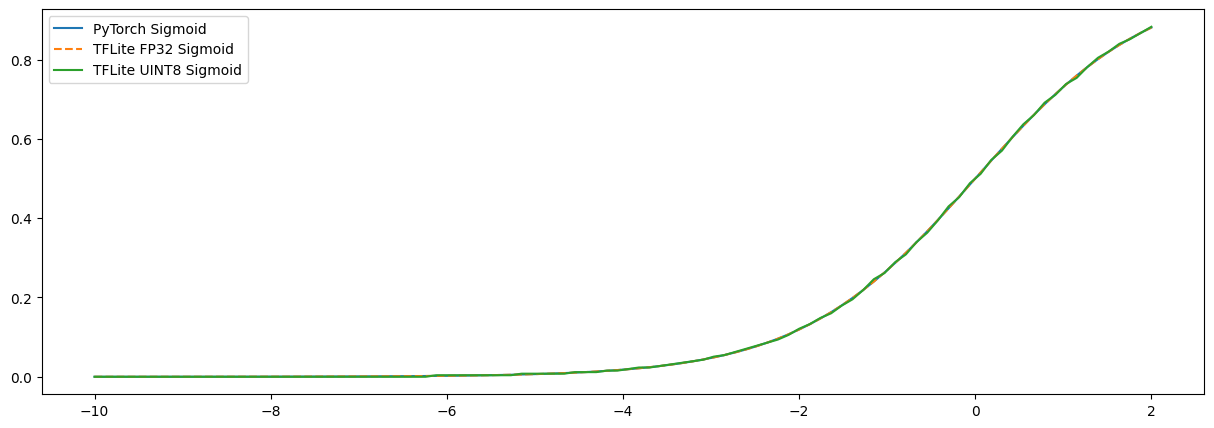

In [154]:
y_fp32 = infer(model_fp32, x[None])[0]
# y_uint8 = infer(model_uint8, (x_norm[None].numpy()).astype(np.uint8))[0]
# y_uint8 = infer(model_uint8, (np.array(sorted(a))[None]).astype(np.uint8))[0]
y_uint8 = infer(model_uint8, (x_norm[None].numpy()).astype(np.uint8))[0]

plt.figure(figsize=(15, 5))
plt.plot(x.numpy(), y[0], label='PyTorch Sigmoid')
plt.plot(x.numpy(), y_fp32, '--', label='TFLite FP32 Sigmoid')
# plt.plot(np.array(sorted(a)) / 255, y_uint8, label='TFLite UINT8 Sigmoid')
plt.plot(x.numpy(), y_uint8, label='TFLite UINT8 Sigmoid')

plt.legend()

In [118]:
input3 = np.load("head_uint8_saved_model/input_3.npy")
input4 = np.load("head_uint8_saved_model/input_4.npy")
input2 = np.load("head_uint8_saved_model/input_2.npy")

input_tensor = np.hstack([input3, input4, input2])
input_tensor.shape

(100, 2100, 1)

In [119]:
input_tensor.min(), input_tensor.max()

(-105.1385, 2.1369615)

(100, 100, 64) 0.0 255.0
(100, 100, 1) 0.0 43.0
(100, 1600, 64) 0.0 255.0
(100, 1600, 1) 0.0 254.0
(100, 400, 64) 0.0 254.0
(100, 2100, 2) 0.0 247.0
(100, 400, 1) 3.0 254.0


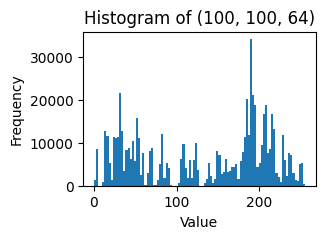

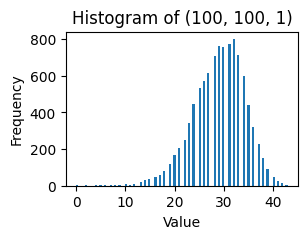

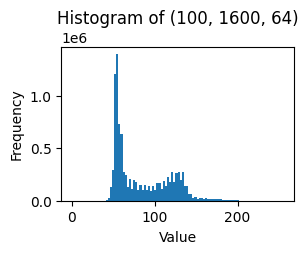

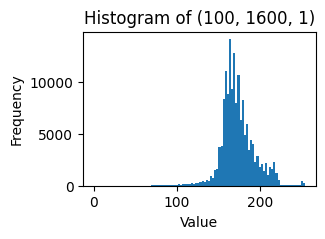

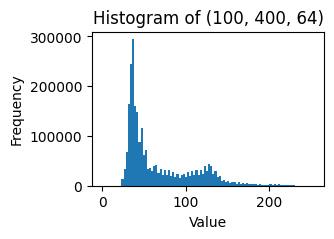

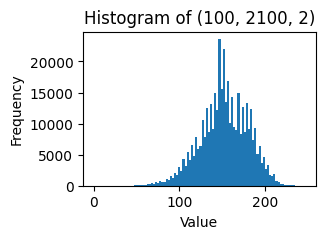

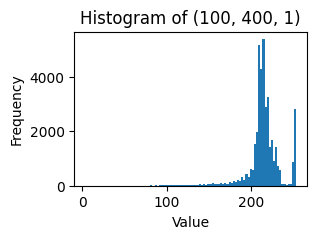

In [120]:
input_tensors = []
for i in glob.glob("head_uint8_quant_input_norm_saved_model/input_*_quantized.npy"):
    input_tensors.append(np.load(i))
    
for i in input_tensors:
    print(i.shape, i.min(), i.max())
    
for i in input_tensors:
    plt.figure(figsize=(3, 2))
    plt.hist(i.flatten(), bins=100)
    plt.title(f"Histogram of {i.shape}")
    plt.xlabel("Value")
    plt.ylabel("Frequency")

(100, 1600, 64) -6.45965 16.104881
(100, 100, 64) -0.4463123 2.3295326
(100, 100, 1) -13.692745 -11.383772
(100, 1600, 1) -55.141174 1.793209
(100, 400, 1) -105.1385 2.1369615
(100, 2100, 2) -3.6813326 2.9077191
(100, 400, 64) -4.0054545 14.835016


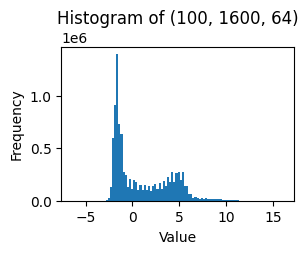

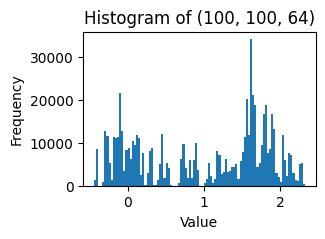

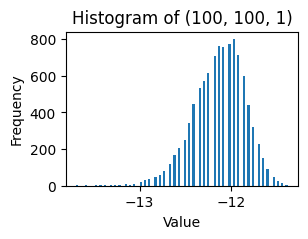

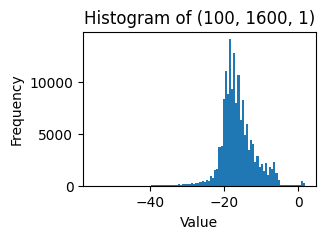

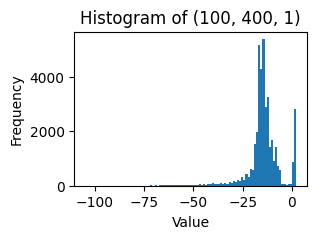

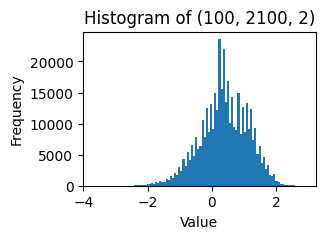

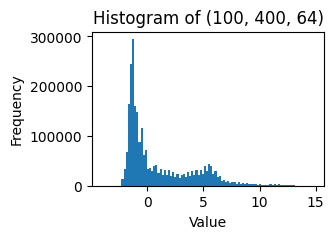

In [121]:
input_tensors = []
for i in range(7):
    input_tensors.append(np.load(f"head_uint8_saved_model/input_{i}.npy"))
    
for i in input_tensors:
    print(i.shape, i.min(), i.max())
    
for i in input_tensors:
    plt.figure(figsize=(3, 2))
    plt.hist(i.flatten(), bins=100)
    plt.title(f"Histogram of {i.shape}")
    plt.xlabel("Value")
    plt.ylabel("Frequency")